# 00route: the PanStar Acro voyage, Busan to Europe and back

Builds the route the globe page animates: a hand-drawn track through the Northern Sea Route (NSR), timed from the published dates and distances, and a "ghost" ship sailing the same days via Suez.

**This is a reconstruction, not the ship's real track.** Waypoints are drawn by hand; the timing assumes one steady sailing speed and fixed port stays. The page says so.

Output: `docs/data/route.json`, read by `docs/index.html`. It also carries the published facts the page shows (cargo, capacity, distance, source), so each number lives in one place: Section 0 below.

## Section 0: settings

Everything you may want to change is here, marked `# <-`.

Waypoints are `(name, longitude, latitude, port stay in days)`. Leave the name empty for a plain turning point. Longitudes are normal (-180 to 180); the notebook handles the jump across the date line near the Bering Strait.

The outward and home routes are separate lists, since the ship called at Felixstowe and Rotterdam only on the way out. The Northern Sea Route (NSR) starts and ends at two gates: Cape Zhelaniya at the northern tip of Novaya Zemlya (west) and the Bering Strait (east). When the track passes a gate waypoint, the ship enters or leaves the NSR.

In [ ]:
DEPART = "2026-08-22"  # <- left Busan
RETURN = "2026-10-11"  # <- back in Busan
STEP_KM = 40  # <- spacing of points along the track (smaller = smoother, bigger file)
OUT_FILE = "docs/data/route.json"  # <-

# Published figures, used only for checks (nautical miles)
PUBLISHED_NM = {
    "Busan to Felixstowe (NSR)": 7577,
    "Gdansk to Busan (NSR)": 7660,
    "Round trip": 16385,
    "Busan to Felixstowe (Suez, planning)": 10877,
}
PUBLISHED_NSR_DAYS = 6  # <- "about 6 days" in the Arctic each way, for checks only

# Published facts shown on the page (all from the source below) # <-
FACTS = {
    "vessel": "PanStar Acro",
    "operator": "PanStar",
    "capacity_teu": 2758,
    "cargo_out_teu": 737,
    "cargo_hoped_teu": 1300,
    "empties_back_teu": 1743,
    "distance_nm": 16385,
    "nsr_speed_knots": 15,
    "source": "Arctic Portal, 23 October 2026, citing Reuters and the Centre for High North Logistics",
    "source_url": "https://arcticportal.org/news-events/news/4175-south-korean-ship-completes-arctic-trade-voyage",
}

NSR_GATES = ["Bering Strait", "Cape Zhelaniya"]  # <- waypoint names where the NSR starts or ends

# Outward route, Busan to Gdansk # <-
OUTWARD = [
    ("Busan", 129.08, 35.06, 0),
    ("", 129.4, 34.95, 0),
    ("", 130.6, 36.8, 0),
    ("", 134.5, 40.2, 0),
    ("", 139.6, 41.35, 0),
    ("Tsugaru Strait", 140.5, 41.4, 0),
    ("", 141.65, 41.6, 0),
    ("", 143.3, 41.6, 0),
    ("", 145.5, 42.4, 0),
    ("", 152.0, 46.0, 0),
    ("", 160.5, 51.0, 0),
    ("", 167.0, 55.5, 0),
    ("", 176.0, 60.5, 0),
    ("", -178.0, 62.5, 0),
    ("", -172.6, 64.05, 0),
    ("", -170.4, 65.3, 0),
    ("Bering Strait", -169.0, 66.1, 0),
    ("", -170.5, 67.6, 0),
    ("", -174.0, 68.8, 0),
    ("", 180.0, 70.2, 0),
    ("", 172.0, 70.4, 0),
    ("", 165.0, 71.5, 0),
    ("", 155.0, 73.0, 0),
    ("", 148.0, 74.1, 0),
    ("", 142.0, 74.35, 0),
    ("", 138.0, 74.3, 0),
    ("", 130.0, 75.0, 0),
    ("", 120.0, 76.6, 0),
    ("", 113.0, 77.2, 0),
    ("Vilkitsky Strait", 104.5, 77.9, 0),
    ("", 96.0, 77.4, 0),
    ("", 85.0, 76.6, 0),
    ("", 75.0, 77.2, 0),
    ("Cape Zhelaniya", 69.0, 77.3, 0),
    ("", 60.0, 76.4, 0),
    ("", 50.0, 74.5, 0),
    ("", 38.0, 72.6, 0),
    ("North Cape", 26.0, 71.7, 0),
    ("", 21.0, 71.2, 0),
    ("", 16.0, 70.0, 0),
    ("", 11.0, 68.3, 0),
    ("", 9.5, 66.0, 0),
    ("", 4.5, 62.0, 0),
    ("", 3.0, 57.0, 0),
    ("", 2.6, 53.5, 0),
    ("", 1.9, 51.85, 0),
    ("Felixstowe", 1.33, 51.95, 1.5),
    ("Rotterdam", 4.05, 51.97, 1.5),
    ("", 3.9, 52.25, 0),
    ("", 4.3, 53.0, 0),
    ("", 6.0, 54.4, 0),
    ("", 8.0, 57.2, 0),
    ("", 10.6, 57.9, 0),
    ("", 11.9, 56.6, 0),
    ("", 12.62, 56.05, 0),
    ("", 12.86, 55.72, 0),
    ("", 12.9, 55.25, 0),
    ("", 14.6, 54.9, 0),
    ("", 15.5, 54.85, 0),
    ("", 17.5, 55.0, 0),
    ("", 18.95, 54.7, 0),
    ("Gdansk", 18.66, 54.40, 1.5),
]

# Way home, Gdansk to Busan: out of the Baltic, straight up the Norwegian coast # <-
HOME = [
    ("Gdansk", 18.66, 54.40, 0),
    ("", 18.95, 54.7, 0),
    ("", 17.5, 55.0, 0),
    ("", 15.5, 54.85, 0),
    ("", 14.6, 54.9, 0),
    ("", 12.9, 55.25, 0),
    ("", 12.86, 55.72, 0),
    ("", 12.62, 56.05, 0),
    ("", 11.9, 56.6, 0),
    ("Skagen", 10.6, 57.9, 0),
    ("", 7.0, 57.75, 0),
    ("", 5.0, 58.5, 0),
    ("", 4.6, 59.6, 0),
    ("", 4.5, 62.0, 0),
    ("", 9.5, 66.0, 0),
    ("", 11.0, 68.3, 0),
    ("", 16.0, 70.0, 0),
    ("", 21.0, 71.2, 0),
    ("North Cape", 26.0, 71.7, 0),
    ("", 38.0, 72.6, 0),
    ("", 50.0, 74.5, 0),
    ("", 60.0, 76.4, 0),
    ("Cape Zhelaniya", 69.0, 77.3, 0),
    ("", 75.0, 77.2, 0),
    ("", 85.0, 76.6, 0),
    ("", 96.0, 77.4, 0),
    ("Vilkitsky Strait", 104.5, 77.9, 0),
    ("", 113.0, 77.2, 0),
    ("", 120.0, 76.6, 0),
    ("", 130.0, 75.0, 0),
    ("", 138.0, 74.3, 0),
    ("", 142.0, 74.35, 0),
    ("", 148.0, 74.1, 0),
    ("", 155.0, 73.0, 0),
    ("", 165.0, 71.5, 0),
    ("", 172.0, 70.4, 0),
    ("", 180.0, 70.2, 0),
    ("", -174.0, 68.8, 0),
    ("", -170.5, 67.6, 0),
    ("Bering Strait", -169.0, 66.1, 0),
    ("", -170.4, 65.3, 0),
    ("", -172.6, 64.05, 0),
    ("", -178.0, 62.5, 0),
    ("", 176.0, 60.5, 0),
    ("", 167.0, 55.5, 0),
    ("", 160.5, 51.0, 0),
    ("", 152.0, 46.0, 0),
    ("", 145.5, 42.4, 0),
    ("", 143.3, 41.6, 0),
    ("", 141.65, 41.6, 0),
    ("Tsugaru Strait", 140.5, 41.4, 0),
    ("", 139.6, 41.35, 0),
    ("", 134.5, 40.2, 0),
    ("", 130.6, 36.8, 0),
    ("", 129.4, 34.95, 0),
    ("Busan", 129.08, 35.06, 0),
]

# Ghost ship via Suez, Busan to Felixstowe only (same speed as the Arctic ship). # <-
SUEZ = [
    ("Busan", 129.08, 35.06, 0),
    ("", 129.0, 34.6, 0),
    ("", 125.5, 31.5, 0),
    ("Taiwan Strait", 119.8, 24.0, 0),
    ("", 114.5, 16.0, 0),
    ("", 108.5, 8.0, 0),
    ("", 104.6, 1.6, 0),
    ("Singapore", 103.75, 1.15, 0),
    ("", 102.3, 1.95, 0),
    ("", 101.0, 2.7, 0),
    ("", 100.0, 3.6, 0),
    ("", 98.6, 5.0, 0),
    ("", 97.0, 6.0, 0),
    ("", 86.0, 6.0, 0),
    ("", 80.5, 5.6, 0),
    ("", 72.0, 9.0, 0),
    ("", 60.0, 12.9, 0),
    ("", 55.0, 13.6, 0),
    ("", 52.0, 12.9, 0),
    ("Bab el-Mandeb", 43.4, 12.6, 0),
    ("", 38.5, 20.0, 0),
    ("", 34.0, 27.0, 0),
    ("Suez Canal", 32.55, 30.0, 0),
    ("", 32.3, 31.4, 0),
    ("", 25.0, 34.0, 0),
    ("", 15.0, 36.6, 0),
    ("", 9.0, 37.6, 0),
    ("", 0.0, 37.0, 0),
    ("Gibraltar", -5.6, 35.95, 0),
    ("", -9.2, 36.75, 0),
    ("", -9.8, 38.0, 0),
    ("", -9.8, 43.2, 0),
    ("", -5.5, 48.6, 0),
    ("", -1.0, 50.3, 0),
    ("", 1.6, 51.0, 0),
    ("", 1.9, 51.85, 0),
    ("Felixstowe", 1.33, 51.95, 0),
]

PORTS = ["Busan", "Felixstowe", "Rotterdam", "Gdansk"]  # <- shown as ports on the page

## 1. Imports

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Helpers

Distances are great-circle distances on a sphere (radius 6,371 km). Between two waypoints, points are placed along the great circle, so the line follows the curve of the Earth on the globe.

In [ ]:
EARTH_KM = 6371.0
KM_PER_NM = 1.852


def to_xyz(lon, lat):
    lon = np.radians(lon)
    lat = np.radians(lat)
    return np.array([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])


def to_lonlat(v):
    lon = np.degrees(np.arctan2(v[1], v[0]))
    lat = np.degrees(np.arcsin(np.clip(v[2], -1, 1)))
    return lon, lat


def gc_km(a, b):
    """Great-circle distance in km between (lon, lat) points a and b."""
    cos_angle = np.clip(np.dot(to_xyz(*a), to_xyz(*b)), -1, 1)
    return float(np.arccos(cos_angle) * EARTH_KM)


def gc_points(a, b, step_km):
    """Points from a to b along the great circle, about step_km apart (b included, a not)."""
    va = to_xyz(*a)
    vb = to_xyz(*b)
    angle = np.arccos(np.clip(np.dot(va, vb), -1, 1))
    n = max(1, int(np.ceil(angle * EARTH_KM / step_km)))
    out = []
    for i in range(1, n + 1):
        f = i / n
        v = (np.sin((1 - f) * angle) * va + np.sin(f * angle) * vb) / np.sin(angle)
        out.append(to_lonlat(v))
    return out


def unwrap(lons):
    """Remove the 360 degree jump at the date line, so the track is continuous."""
    return list(np.degrees(np.unwrap(np.radians(lons))))

## 3. The Arctic round trip

The outward and home lists are joined at Gdansk. Sailing time is the whole voyage minus the port stays, and one steady speed fills it.

In [ ]:
stops = OUTWARD + HOME[1:]
stops_df = pd.DataFrame(stops, columns=["name", "lon", "lat", "stay_days"])
stops_df["leg_km"] = [0.0] + [gc_km(stops[i][1:3], stops[i + 1][1:3]) for i in range(len(stops) - 1)]

total_days = (pd.Timestamp(RETURN) - pd.Timestamp(DEPART)).days
port_days = stops_df["stay_days"].sum()
sail_days = total_days - port_days
total_km = stops_df["leg_km"].sum()
km_per_day = total_km / sail_days
knots = km_per_day / KM_PER_NM / 24

print(f"Voyage: {total_days} days, of which {port_days} in port and {sail_days} at sea")
print(f"Route length: {total_km / KM_PER_NM:,.0f} nm, steady speed {knots:.1f} knots")

Voyage: 50 days, of which 4.5 in port and 45.5 at sea
Route length: 16,034 nm, steady speed 14.7 knots


In [ ]:
def build_track(stops, km_per_day, step_km):
    """Densified path with a time stamp (days since departure) for every point, plus port events."""
    lons = [stops[0][1]]
    lats = [stops[0][2]]
    days = [0.0]
    events = []
    t = 0.0
    for i in range(len(stops) - 1):
        a = stops[i]
        b = stops[i + 1]
        pts = gc_points(a[1:3], b[1:3], step_km)
        leg_days = gc_km(a[1:3], b[1:3]) / km_per_day
        for j, (lon, lat) in enumerate(pts, start=1):
            lons.append(lon)
            lats.append(lat)
            days.append(t + leg_days * j / len(pts))
        t = days[-1]
        if b[0] in NSR_GATES:
            events.append({"name": b[0], "kind": "gate", "day": round(t, 3)})
        if b[0] in PORTS:
            events.append({"name": b[0], "kind": "arrive", "day": round(t, 3)})
        if b[3] > 0:
            t = t + b[3]
            lons.append(lons[-1])
            lats.append(lats[-1])
            days.append(t)
            events.append({"name": b[0], "kind": "depart", "day": round(t, 3)})
    track = pd.DataFrame({"lon": unwrap(lons), "lat": lats, "day": days})
    return track, events


arctic, arctic_events = build_track(stops, km_per_day, STEP_KM)
pd.DataFrame(arctic_events)

,name,kind,day
0,Bering Strait,gate,8.648
1,Cape Zhelaniya,gate,14.863
2,Felixstowe,arrive,21.130
3,Felixstowe,depart,22.630
4,Rotterdam,arrive,22.915
5,Rotterdam,depart,24.415
6,Gdansk,arrive,26.854
7,Gdansk,depart,28.354
8,Cape Zhelaniya,gate,35.137
9,Bering Strait,gate,41.352


## 4. The ghost ship via Suez

In [ ]:
suez, suez_events = build_track(SUEZ, km_per_day, STEP_KM)
suez_km = sum(gc_km(SUEZ[i][1:3], SUEZ[i + 1][1:3]) for i in range(len(SUEZ) - 1))
print(f"Suez route: {suez_km / KM_PER_NM:,.0f} nm, reaches Felixstowe on day {suez['day'].iloc[-1]:.1f}")

Suez route: 10,793 nm, reaches Felixstowe on day 30.6


## 5. Checks against the published figures

The hand-drawn route should come within a few percent of the published distances. If a difference is large, move waypoints in Section 0.

In [ ]:
def leg_nm(stops, start, end):
    """Distance from the first stop called start to the next stop called end."""
    names = [s[0] for s in stops]
    i = names.index(start)
    j = names.index(end, i + 1)
    return sum(gc_km(stops[k][1:3], stops[k + 1][1:3]) for k in range(i, j)) / KM_PER_NM


gdansk_out = [s[0] for s in stops].index("Gdansk")
ours = {
    "Busan to Felixstowe (NSR)": leg_nm(stops, "Busan", "Felixstowe"),
    "Gdansk to Busan (NSR)": leg_nm(stops[gdansk_out:], "Gdansk", "Busan"),
    "Round trip": total_km / KM_PER_NM,
    "Busan to Felixstowe (Suez, planning)": suez_km / KM_PER_NM,
}
checks = pd.DataFrame({"published_nm": PUBLISHED_NM, "ours_nm": ours})
checks["difference_pct"] = (checks["ours_nm"] / checks["published_nm"] - 1) * 100
checks.round(1)

,published_nm,ours_nm,difference_pct
Busan to Felixstowe (NSR),7577,7446.0,-1.7
Gdansk to Busan (NSR),7660,7628.1,-0.4
Round trip,16385,16034.2,-2.1
"Busan to Felixstowe (Suez, planning)",10877,10792.8,-0.8


In [ ]:
felix_arctic = [e["day"] for e in arctic_events if e["name"] == "Felixstowe" and e["kind"] == "arrive"][0]
felix_suez = suez["day"].iloc[-1]
print(f"Felixstowe reached on day {felix_arctic:.1f} via the Arctic and day {felix_suez:.1f} via Suez")
print(f"Days saved westbound: {felix_suez - felix_arctic:.1f} ({(1 - felix_arctic / felix_suez) * 100:.0f}% shorter)")

Felixstowe reached on day 21.1 via the Arctic and day 30.6 via Suez
Days saved westbound: 9.5 (31% shorter)


### The Arctic passage

Gate events come in pairs: the first opens a passage through the NSR, the second closes it.

In [ ]:
gates = [e for e in arctic_events if e["kind"] == "gate"]
passages = []
for i in range(0, len(gates) - 1, 2):
    start = gates[i]
    end = gates[i + 1]
    passages.append({
        "direction": "westbound" if i == 0 else "eastbound",
        "enter": start["name"],
        "enter_day": start["day"],
        "leave": end["name"],
        "leave_day": end["day"],
        "days": round(end["day"] - start["day"], 2),
        "published_days": PUBLISHED_NSR_DAYS,
    })
passages_df = pd.DataFrame(passages)
nsr_nm = leg_nm(stops, NSR_GATES[0], NSR_GATES[1])
print(f"NSR length on our track: {nsr_nm:,.0f} nm")
passages_df

NSR length on our track: 2,190 nm


,direction,enter,enter_day,leave,leave_day,days,published_days
0,westbound,Bering Strait,8.648,Cape Zhelaniya,14.863,6.22,6
1,eastbound,Cape Zhelaniya,35.137,Bering Strait,41.352,6.21,6


## 6. Check map (flat, for a quick look only)

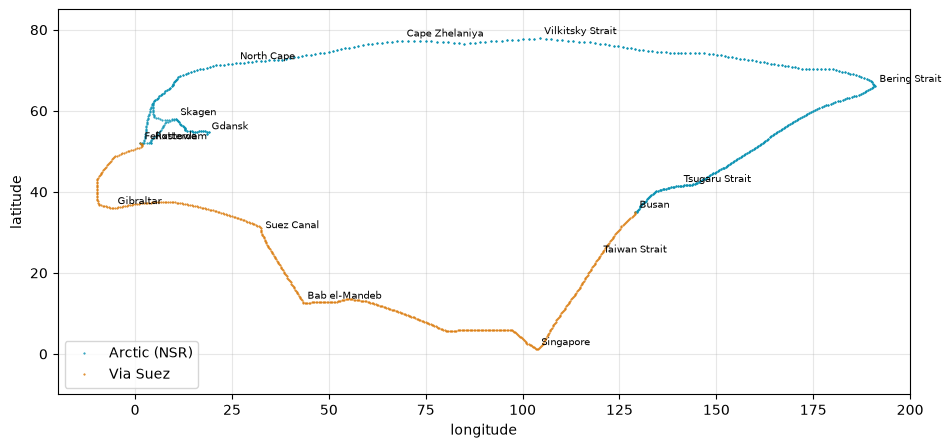

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(arctic["lon"], arctic["lat"], ".", ms=1, color="#0891b2", label="Arctic (NSR)")  # VISUAL:
ax.plot(suez["lon"], suez["lat"], ".", ms=1, color="#d97706", label="Via Suez")  # VISUAL:
shown = []
for name, lon, lat, stay in OUTWARD + HOME + SUEZ:
    if name and name not in shown:
        shown.append(name)
        lon = lon + 360 if lon < -30 else lon
        ax.annotate(name, (lon, lat), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(-20, 200)  # VISUAL: east of 180 shown as 180+
ax.set_ylim(-10, 85)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.show()

## 7. Write `route.json`

Times are days since departure. Longitudes are unwrapped (they can go past 180 near the Bering Strait), which the globe handles.

In [ ]:
labels = []
for name, lon, lat, stay in OUTWARD + HOME + SUEZ:
    if name and name not in PORTS and name not in [d["name"] for d in labels]:
        labels.append({"name": name, "lon": lon, "lat": lat, "gate": name in NSR_GATES})

out = {
    "depart": DEPART,
    "return": RETURN,
    "total_days": total_days,
    "knots": round(knots, 2),
    "arctic": {"path": arctic[["lon", "lat"]].round(4).values.tolist(), "t": arctic["day"].round(4).tolist()},
    "suez": {"path": suez[["lon", "lat"]].round(4).values.tolist(), "t": suez["day"].round(4).tolist()},
    "events": arctic_events,
    "ports": [{"name": n, "lon": lon, "lat": lat} for n, lon, lat, s in OUTWARD if n in PORTS],
    "passages": passages,
    "nsr_gates": NSR_GATES,
    "labels": labels,
    "checks": {k: round(v, 1) for k, v in ours.items()},
    "felixstowe_day": {"arctic": round(felix_arctic, 2), "suez": round(felix_suez, 2)},
    "facts": FACTS,
}
Path(OUT_FILE).parent.mkdir(parents=True, exist_ok=True)
with open(OUT_FILE, "w") as f:
    json.dump(out, f)
print(f"Saved {OUT_FILE}: {Path(OUT_FILE).stat().st_size / 1024:.0f} KB, {len(arctic)} + {len(suez)} points")

Saved docs/data/route.json: 39 KB, 805 + 519 points


___
**END**